In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pickle

with open(
    "/content/drive/MyDrive/Colab Notebooks/beth_prepared.pkl",
    "rb"
) as f:
    dati_preparati = pickle.load(f)

X_train_rel = dati_preparati["X_train_rel"]
X_validation_rel = dati_preparati["X_validation_rel"]
X_test_rel = dati_preparati["X_test_rel"]

y_train = dati_preparati["y_train"]
y_validation = dati_preparati["y_validation"]
y_test = dati_preparati["y_test"]

event_features = dati_preparati["event_features"]

print("TRAIN:", X_train_rel.shape)
print("VALIDATION:", X_validation_rel.shape)
print("TEST:", X_test_rel.shape)

TRAIN: (128, 32)
VALIDATION: (22, 32)
TEST: (13, 32)


La standardizzazione per One-Class SVM è particolarmente importante perché il modello, soprattutto con kernel RBF, dipende dalle distanze tra osservazioni.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler_ocsvm = StandardScaler()

Xs_train_ocsvm = scaler_ocsvm.fit_transform(X_train_rel)
Xs_validation_ocsvm = scaler_ocsvm.transform(X_validation_rel)
Xs_test_ocsvm = scaler_ocsvm.transform(X_test_rel)

print("TRAIN standardizzato:", Xs_train_ocsvm.shape)
print("VALIDATION standardizzato:", Xs_validation_ocsvm.shape)
print("TEST standardizzato:", Xs_test_ocsvm.shape)

TRAIN standardizzato: (128, 32)
VALIDATION standardizzato: (22, 32)
TEST standardizzato: (13, 32)


In [ ]:
from sklearn.svm import OneClassSVM

ocsvm_model = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.05
)

ocsvm_model.fit(Xs_train_ocsvm)

print("One-Class SVM addestrata.")

One-Class SVM addestrata.


Qui:

kernel="rbf" permette una frontiera non lineare, adatta a pattern complessi nelle 32 feature;

gamma="scale" lascia a scikit-learn una scala del kernel dipendente dai dati, evitando di fissare arbitrariamente un valore numerico;

nu=0.05 è invece una scelta da trattare come iperparametro, non come valore “corretto”: controlla, in termini teorici, un limite superiore alla frazione di training errors e un limite inferiore alla frazione di support vectors.

Usiamo 0.5 come baseline


Ora calcoliamo gli score della One-Class SVM su TRAIN, VALIDATION e TEST, e li orientiamo come abbiamo fatto con LOF: score più alto = più anomalo.

Con OneClassSVM, decision_function() restituisce valori in cui in genere positivi = più normali e negativi = più anomali rispetto alla frontiera imparata. Quindi cambiamo segno.

In [ ]:
# Score originali della One-Class SVM
score_train_ocsvm = ocsvm_model.decision_function(Xs_train_ocsvm)
score_validation_ocsvm = ocsvm_model.decision_function(Xs_validation_ocsvm)
score_test_ocsvm = ocsvm_model.decision_function(Xs_test_ocsvm)

# Convenzione comune:
# score più alto = più anomalo
anomaly_score_train_ocsvm = -score_train_ocsvm
anomaly_score_validation_ocsvm = -score_validation_ocsvm
anomaly_score_test_ocsvm = -score_test_ocsvm

print("TRAIN:", anomaly_score_train_ocsvm.shape)
print("VALIDATION:", anomaly_score_validation_ocsvm.shape)
print("TEST:", anomaly_score_test_ocsvm.shape)

print("\nAnomaly score TEST:")
for i, score in enumerate(anomaly_score_test_ocsvm):
    print(f"Window {i}: {score:.6f}")

TRAIN: (128,)
VALIDATION: (22,)
TEST: (13,)

Anomaly score TEST:
Window 0: 0.429137
Window 1: 0.073892
Window 2: -0.001897
Window 3: 0.023707
Window 4: -0.024304
Window 5: 0.429137
Window 6: -0.056483
Window 7: 0.346429
Window 8: 0.039085
Window 9: 0.429128
Window 10: 0.429042
Window 11: 0.429137
Window 12: 0.429137


Gli score sono interessanti: diverse finestre (0, 5, 9, 10, 11, 12) sono quasi tutte attorno a 0.429, quindi la One-Class SVM baseline le considera fortemente anomale rispetto alla frontiera appresa.

Calcoliamo le AUC SUS ed EVIL

Queste saranno per ora le AUC della baseline nu=0.05, non necessariamente quelle definitive.

In [ ]:
from sklearn.metrics import roc_auc_score

y_test_sus = y_test["sus_window"].astype(int).values
y_test_evil = y_test["evil_window"].astype(int).values

auc_sus_ocsvm = roc_auc_score(
    y_test_sus,
    anomaly_score_test_ocsvm
)

auc_evil_ocsvm = roc_auc_score(
    y_test_evil,
    anomaly_score_test_ocsvm
)

print(f"AUC SUS - One-Class SVM:  {auc_sus_ocsvm:.3f}")
print(f"AUC EVIL - One-Class SVM: {auc_evil_ocsvm:.3f}")

AUC SUS - One-Class SVM:  0.690
AUC EVIL - One-Class SVM: 0.900


| Modello                       |   AUC SUS |  AUC EVIL |
| ----------------------------- | --------: | --------: |
| Isolation Forest              |     0.643 |     0.825 |
| LOF standardizzato            |     0.548 |     0.825 |
| **One-Class SVM (`nu=0.05`)** | **0.690** | **0.900** |


Quindi finora One-Class SVM ha l'AUC più alta sia per SUS sia per EVIL. Ma attenzione: nu=0.05 era una baseline, quindi prima di dichiarare questi risultati definitivi dobbiamo gestire l'iperparametro nu.

La cosa corretta è confrontare alcuni valori di nu usando TRAIN + VALIDATION, senza scegliere nulla guardando il TEST. Per SUS possiamo sfruttare le 2 finestre positive della validation; per EVIL no, perché sappiamo che la validation non contiene positivi.

C'è comunque una limitazione importante: abbiamo solo 2 finestre SUS positive in validation, quindi la scelta di nu sarà inevitabilmente poco robusta.

In [ ]:
import numpy as np
from sklearn.svm import OneClassSVM
from sklearn.metrics import roc_auc_score

nu_values = [0.01, 0.03, 0.05, 0.10, 0.15, 0.20]

y_val_sus = y_validation["sus_window"].astype(int).values

risultati_nu = []

for nu in nu_values:

    model = OneClassSVM(
        kernel="rbf",
        gamma="scale",
        nu=nu
    )

    model.fit(Xs_train_ocsvm)

    # Score VALIDATION orientato:
    # maggiore = più anomalo
    val_scores = -model.decision_function(Xs_validation_ocsvm)

    auc_val_sus = roc_auc_score(
        y_val_sus,
        val_scores
    )

    risultati_nu.append((nu, auc_val_sus))

    print(
        f"nu={nu:.2f} -> "
        f"AUC SUS validation={auc_val_sus:.3f}"
    )

nu=0.01 -> AUC SUS validation=0.500
nu=0.03 -> AUC SUS validation=0.500
nu=0.05 -> AUC SUS validation=0.500
nu=0.10 -> AUC SUS validation=0.500
nu=0.15 -> AUC SUS validation=0.500
nu=0.20 -> AUC SUS validation=0.600


Questo risultato ci dice una cosa precisa: la validation discrimina pochissimo tra i valori di nu.

Da 0.01 a 0.15 otteniamo sempre AUC SUS = 0.500; solo nu=0.20 sale a 0.600. Quindi, seguendo il criterio che abbiamo appena stabilito — massimizzare l'AUC SUS sulla validation — nu=0.20 è il candidato selezionato.

Ora dobbiamo riaddestrare il modello definitivo con nu=0.20 e ricalcolare gli score. Le AUC TEST 0.690 / 0.900 appartengono al modello baseline nu=0.05 e quindi non dobbiamo più trattarle come definitive.

---



In [ ]:
from sklearn.svm import OneClassSVM

# Modello definitivo scelto tramite VALIDATION
best_nu = 0.20

ocsvm_model = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=best_nu
)

# Training esclusivamente sul TRAIN
ocsvm_model.fit(Xs_train_ocsvm)

# Nuovi score
anomaly_score_train_ocsvm = -ocsvm_model.decision_function(
    Xs_train_ocsvm
)

anomaly_score_validation_ocsvm = -ocsvm_model.decision_function(
    Xs_validation_ocsvm
)

anomaly_score_test_ocsvm = -ocsvm_model.decision_function(
    Xs_test_ocsvm
)

print("Modello definitivo One-Class SVM")
print("nu =", best_nu)

print("\nTRAIN:", anomaly_score_train_ocsvm.shape)
print("VALIDATION:", anomaly_score_validation_ocsvm.shape)
print("TEST:", anomaly_score_test_ocsvm.shape)

Modello definitivo One-Class SVM
nu = 0.2

TRAIN: (128,)
VALIDATION: (22,)
TEST: (13,)


Poi ricalcoliamo una sola volta le AUC sul TEST del modello selezionato:

In [ ]:
from sklearn.metrics import roc_auc_score

y_test_sus = y_test["sus_window"].astype(int).values
y_test_evil = y_test["evil_window"].astype(int).values

auc_sus_ocsvm = roc_auc_score(
    y_test_sus,
    anomaly_score_test_ocsvm
)

auc_evil_ocsvm = roc_auc_score(
    y_test_evil,
    anomaly_score_test_ocsvm
)

print(f"AUC SUS definitiva - One-Class SVM:  {auc_sus_ocsvm:.3f}")
print(f"AUC EVIL definitiva - One-Class SVM: {auc_evil_ocsvm:.3f}")

AUC SUS definitiva - One-Class SVM:  0.690
AUC EVIL definitiva - One-Class SVM: 0.900


Il fatto che le AUC TEST siano rimaste esattamente 0.690 e 0.900 anche passando da nu=0.05 a nu=0.20 non è necessariamente strano: l'AUC dipende dall'ordinamento degli score, non dai loro valori assoluti. nu può aver cambiato gli score senza modificarne abbastanza il ranking tra le 13 finestre.

Quindi per ora i risultati definitivi OCSVM sono:

| Modello                       |   AUC SUS |  AUC EVIL |
| ----------------------------- | --------: | --------: |
| Isolation Forest              |     0.643 |     0.825 |
| LOF                           |     0.548 |     0.825 |
| **One-Class SVM (`nu=0.20`)** | **0.690** | **0.900** |


One-Class SVM è quindi, finora, il migliore dei tre in termini di AUC sia SUS sia EVIL.

Ora seguiamo lo stesso percorso degli altri modelli: ROC → soglie TRAIN → validation → TEST → sensibilità feature → salvataggio.

Prima facciamo la ROC definitiva:

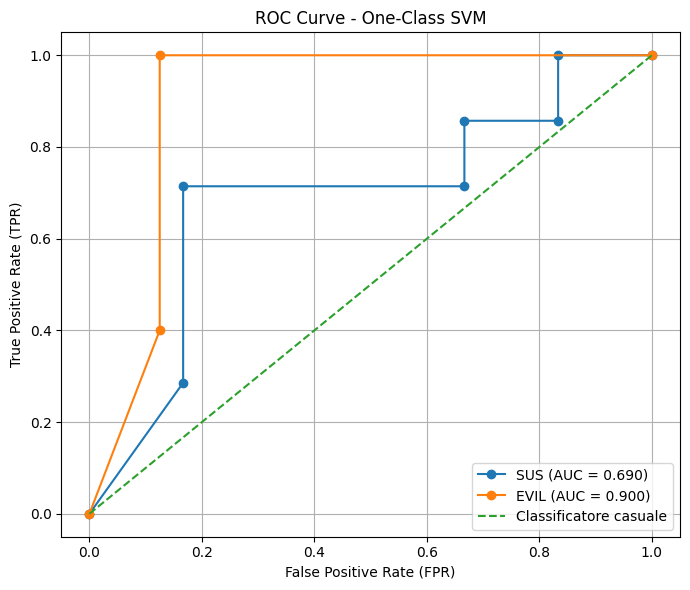

In [ ]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr_sus_ocsvm, tpr_sus_ocsvm, _ = roc_curve(
    y_test_sus,
    anomaly_score_test_ocsvm
)

fpr_evil_ocsvm, tpr_evil_ocsvm, _ = roc_curve(
    y_test_evil,
    anomaly_score_test_ocsvm
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr_sus_ocsvm,
    tpr_sus_ocsvm,
    marker="o",
    label=f"SUS (AUC = {auc_sus_ocsvm:.3f})"
)

plt.plot(
    fpr_evil_ocsvm,
    tpr_evil_ocsvm,
    marker="o",
    label=f"EVIL (AUC = {auc_evil_ocsvm:.3f})"
)

plt.plot(
    [0, 1], [0, 1],
    "--",
    label="Classificatore casuale"
)

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve - One-Class SVM")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.show()

Perfetto. La ROC è coerente con i risultati: EVIL (0.900) mostra una separazione nettamente migliore di SUS (0.690). La forma a gradini è normale con appena 13 finestre TEST.

Ora passiamo alle soglie candidate, ricavate esclusivamente dagli anomaly score del TRAIN del modello definitivo nu=0.20.

Il principio rimane identico a IF e LOF:

TRAIN → genera le soglie candidate
VALIDATION → serve per scegliere eventualmente la soglia SUS
TEST → solo valutazione finale

Per EVIL avremo ancora la stessa limitazione: la validation contiene 0 finestre EVIL positive, quindi non potremo selezionare una soglia EVIL ottimizzando F1.

In [ ]:
import numpy as np

percentili = [90, 95, 97, 99]

thresholds_ocsvm = {
    p: np.percentile(anomaly_score_train_ocsvm, p)
    for p in percentili
}

print("Soglie candidate One-Class SVM:")

for p, threshold in thresholds_ocsvm.items():
    print(f"{p}% -> {threshold:.6f}")

Soglie candidate One-Class SVM:
90% -> 0.084188
95% -> 0.546494
97% -> 0.988403
99% -> 1.180348


Adesso facciamo la validation SUS, esattamente come per gli altri modelli. Ricordiamo che le vere finestre SUS nella validation sono 0 e 21.

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np

y_val_sus = y_validation["sus_window"].astype(int).values

for p, threshold in thresholds_ocsvm.items():

    pred_val_sus = (
        anomaly_score_validation_ocsvm >= threshold
    ).astype(int)

    precision = precision_score(
        y_val_sus, pred_val_sus, zero_division=0
    )

    recall = recall_score(
        y_val_sus, pred_val_sus, zero_division=0
    )

    f1 = f1_score(
        y_val_sus, pred_val_sus, zero_division=0
    )

    finestre_anomale = np.where(pred_val_sus == 1)[0]

    print(
        f"{p}% | soglia={threshold:.6f} | "
        f"Precision={precision:.3f} | "
        f"Recall={recall:.3f} | "
        f"F1={f1:.3f}"
    )

    print("Finestre segnalate:", finestre_anomale)
    print()

90% | soglia=0.084188 | Precision=0.125 | Recall=0.500 | F1=0.200
Finestre segnalate: [ 0  5  6  8 10 14 16 20]

95% | soglia=0.546494 | Precision=0.250 | Recall=0.500 | F1=0.333
Finestre segnalate: [ 0  6 10 20]

97% | soglia=0.988403 | Precision=0.333 | Recall=0.500 | F1=0.400
Finestre segnalate: [ 0  6 10]

99% | soglia=1.180348 | Precision=0.333 | Recall=0.500 | F1=0.400
Finestre segnalate: [ 0  6 10]



97% e 99% producono addirittura le stesse predizioni [0, 6, 10]. Quindi, su questa validation, sono operativamente equivalenti.

Per evitare una scelta arbitraria, possiamo adottare il 97° percentile: è la soglia meno restrittiva tra quelle a massimo F1. Va però documentato che 97% e 99% erano a pari merito e producevano le stesse predizioni.

In [ ]:
soglia_sus_ocsvm = thresholds_ocsvm[97]

print(f"Soglia SUS selezionata: {soglia_sus_ocsvm:.6f}")
print("Percentile: 97%")

Soglia SUS selezionata: 0.988403
Percentile: 97%


Ora possiamo applicarla una sola volta al TEST:

In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

pred_test_sus_ocsvm = (
    anomaly_score_test_ocsvm >= soglia_sus_ocsvm
).astype(int)

cm_sus_ocsvm = confusion_matrix(
    y_test_sus,
    pred_test_sus_ocsvm
)

precision_sus_ocsvm = precision_score(
    y_test_sus, pred_test_sus_ocsvm, zero_division=0
)

recall_sus_ocsvm = recall_score(
    y_test_sus, pred_test_sus_ocsvm, zero_division=0
)

f1_sus_ocsvm = f1_score(
    y_test_sus, pred_test_sus_ocsvm, zero_division=0
)

print(
    "Finestre SUS predette:",
    np.where(pred_test_sus_ocsvm == 1)[0]
)

print("\nConfusion matrix:")
print(cm_sus_ocsvm)

print(f"\nPrecision: {precision_sus_ocsvm:.3f}")
print(f"Recall:    {recall_sus_ocsvm:.3f}")
print(f"F1:        {f1_sus_ocsvm:.3f}")

Finestre SUS predette: [ 0  1  5  7  9 10 11 12]

Confusion matrix:
[[3 3]
 [2 5]]

Precision: 0.625
Recall:    0.714
F1:        0.667


erfetto. Quindi per SUS, la One-Class SVM definitiva con nu=0.20 e soglia selezionata sulla validation al 97° percentile ottiene sul TEST:

Precision = 0.625, Recall = 0.714, F1 = 0.667, con 5 veri positivi, 2 falsi negativi e 3 falsi positivi.

Le finestre segnalate sono [0, 1, 5, 7, 9, 10, 11, 12]; tra queste, le SUS reali intercettate sono 0, 9, 10, 11, 12. Le SUS 3 e 4 vengono invece perse.

Ora facciamo EVIL. Come per IF e LOF, non possiamo scegliere una soglia EVIL sulla validation perché non contiene positivi EVIL. Quindi analizziamo sul TEST le quattro soglie prefissate dal TRAIN, senza selezionare quella con F1 maggiore:

In [ ]:
y_test_evil = y_test["evil_window"].astype(int).values

for p, threshold in thresholds_ocsvm.items():

    pred_test_evil = (
        anomaly_score_test_ocsvm >= threshold
    ).astype(int)

    cm = confusion_matrix(
        y_test_evil,
        pred_test_evil
    )

    precision = precision_score(
        y_test_evil,
        pred_test_evil,
        zero_division=0
    )

    recall = recall_score(
        y_test_evil,
        pred_test_evil,
        zero_division=0
    )

    f1 = f1_score(
        y_test_evil,
        pred_test_evil,
        zero_division=0
    )

    print(f"\n--- Soglia {p}% ({threshold:.6f}) ---")

    print(
        "Finestre predette anomale:",
        np.where(pred_test_evil == 1)[0]
    )

    print("Confusion matrix:")
    print(cm)

    print(
        f"Precision={precision:.3f} | "
        f"Recall={recall:.3f} | "
        f"F1={f1:.3f}"
    )


--- Soglia 90% (0.084188) ---
Finestre predette anomale: [ 0  1  3  5  7  8  9 10 11 12]
Confusion matrix:
[[3 5]
 [0 5]]
Precision=0.500 | Recall=1.000 | F1=0.667

--- Soglia 95% (0.546494) ---
Finestre predette anomale: [ 0  1  5  7  9 10 11 12]
Confusion matrix:
[[5 3]
 [0 5]]
Precision=0.625 | Recall=1.000 | F1=0.769

--- Soglia 97% (0.988403) ---
Finestre predette anomale: [ 0  1  5  7  9 10 11 12]
Confusion matrix:
[[5 3]
 [0 5]]
Precision=0.625 | Recall=1.000 | F1=0.769

--- Soglia 99% (1.180348) ---
Finestre predette anomale: [ 0  1  5  7  9 10 11 12]
Confusion matrix:
[[5 3]
 [0 5]]
Precision=0.625 | Recall=1.000 | F1=0.769


con le soglie 90–99% tutte e 5 le finestre EVIL vengono intercettate. Dal 95% in poi le predizioni sono identiche [0,1,5,7,9,10,11,12], quindi Recall = 1.000, con tre falsi positivi (1,5,7).

Il risultato F1 = 0.769 al 95/97/99% è interessante, ma resta esplorativo: non scegliamo una soglia EVIL da questi risultati TEST, perché la validation non aveva positivi EVIL.

Ora passiamo all'analisi delle feature, mantenendo esattamente lo stesso principio usato per IF e LOF. Permutiamo ciascuna delle 32 feature sul TRAIN standardizzato e misuriamo quanto cambia l'anomaly score della One-Class SVM.

Stiamo misurando quali feature, quando perturbate, provocano mediamente i cambiamenti maggiori negli anomaly score della One-Class SVM.



In [ ]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
n_repeats = 30

# Baseline sulla VALIDATION
baseline_scores = anomaly_score_validation_ocsvm.copy()

sensibilita_ocsvm = []

for j, feature in enumerate(event_features):

    variazioni = []

    for _ in range(n_repeats):

        X_perm = Xs_validation_ocsvm.copy()

        # Permutiamo una sola feature
        X_perm[:, j] = rng.permutation(X_perm[:, j])

        # Nuovi anomaly score sulla validation perturbata
        perm_scores = -ocsvm_model.decision_function(X_perm)

        variazione = np.mean(
            np.abs(perm_scores - baseline_scores)
        )

        variazioni.append(variazione)

    sensibilita_ocsvm.append({
        "feature": feature,
        "sensitivity_mean": np.mean(variazioni),
        "sensitivity_std": np.std(variazioni)
    })

sensibilita_ocsvm_df = pd.DataFrame(
    sensibilita_ocsvm
).sort_values(
    "sensitivity_mean",
    ascending=False
).reset_index(drop=True)

print(sensibilita_ocsvm_df.head(10).to_string(index=False))

              feature  sensitivity_mean  sensitivity_std
security_inode_unlink          0.281228         0.041634
               unlink          0.258084         0.039928
               access          0.227620         0.039896
                lstat          0.178333         0.035465
   sched_process_exit          0.138026         0.030535
           getdents64          0.128413         0.030513
   security_file_open          0.112905         0.028814
               openat          0.101299         0.022164
                 stat          0.096947         0.018737
                fstat          0.087888         0.023806


L'analisi di sensitivity post-hoc della One-Class SVM, calcolata sulla VALIDATION mediante 30 permutazioni indipendenti per ciascuna feature, mostra che il modello è particolarmente sensibile alla perturbazione di security_inode_unlink e unlink, seguite da access e lstat. Tra le prime dieci compaiono inoltre sched_process_exit, getdents64, security_file_open, openat, stat e fstat.

La sensitivity misura la variazione media assoluta dell'anomaly score provocata dalla perturbazione di una singola feature, mantenendo inalterate le altre. Non rappresenta quindi una feature importance nativa della One-Class SVM né permette di stabilire un rapporto causale tra una feature e l'anomalia. Le deviazioni standard ottenute dalle 30 ripetizioni mostrano inoltre che la misura presenta una certa variabilità e che la graduatoria non deve essere interpretata come rigidamente deterministica.

L'utilizzo della VALIDATION rende questa analisi metodologicamente coerente con quella adottata per LOF e mantiene il TEST separato dall'analisi globale di sensitivity.

Adesso facciamo il grafico top-10, come per gli altri due modelli:

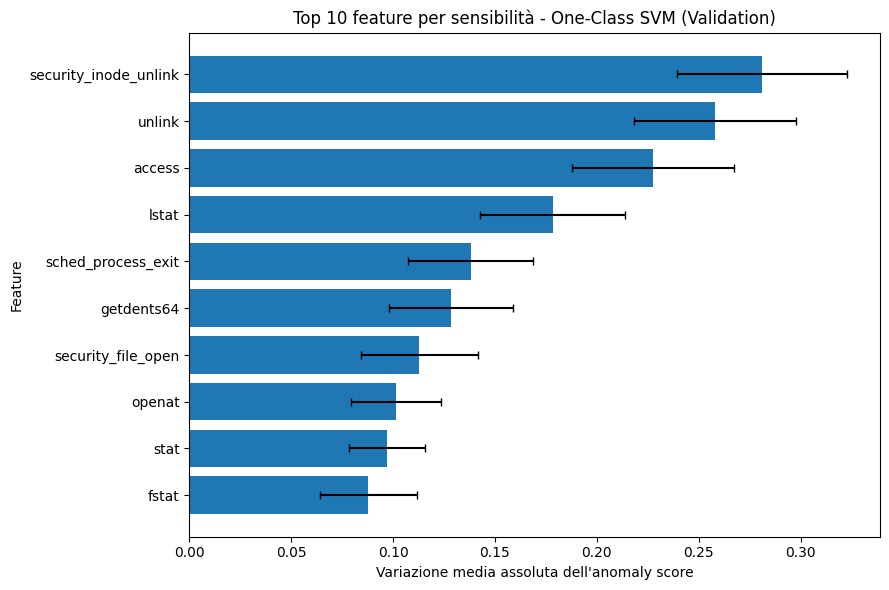

In [ ]:
import matplotlib.pyplot as plt

top10_ocsvm = sensibilita_ocsvm_df.head(10).sort_values(
    "sensitivity_mean",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    top10_ocsvm["feature"],
    top10_ocsvm["sensitivity_mean"],
    xerr=top10_ocsvm["sensitivity_std"],
    capsize=3
)

plt.xlabel("Variazione media assoluta dell'anomaly score")
plt.ylabel("Feature")
plt.title("Top 10 feature per sensibilità - One-Class SVM (Validation)")

plt.tight_layout()
plt.show()

Ora facciamo il profilo delle top-10 feature sulle 13 finestre di TEST. Qui usiamo X_test_rel, quindi le frequenze relative originali e interpretabili, non i valori standardizzati.

In [ ]:
# Top 10 feature secondo la sensitivity OCSVM sulla VALIDATION
top10_features_ocsvm = (
    sensibilita_ocsvm_df
    .head(10)["feature"]
    .tolist()
)

# Profilo TEST usando le frequenze relative originali
if hasattr(X_test_rel, "loc"):
    test_profile_ocsvm = X_test_rel[
        top10_features_ocsvm
    ].copy()
else:
    top10_idx_ocsvm = [
        list(event_features).index(feature)
        for feature in top10_features_ocsvm
    ]

    test_profile_ocsvm = pd.DataFrame(
        X_test_rel[:, top10_idx_ocsvm],
        columns=top10_features_ocsvm
    )

# Aggiungiamo score e label reali
test_profile_ocsvm.insert(
    0, "EVIL_reale",
    y_test["evil_window"].astype(int).values
)

test_profile_ocsvm.insert(
    0, "SUS_reale",
    y_test["sus_window"].astype(int).values
)

test_profile_ocsvm.insert(
    0, "anomaly_score_ocsvm",
    anomaly_score_test_ocsvm
)

test_profile_ocsvm.insert(
    0, "window",
    range(len(test_profile_ocsvm))
)

print(test_profile_ocsvm.to_string(index=False))

 window  anomaly_score_ocsvm  SUS_reale  EVIL_reale  security_inode_unlink   unlink   access    lstat  sched_process_exit  getdents64  security_file_open   openat     stat    fstat
      0             2.243385          1           1               0.008465 0.004938 0.007054 0.029626            0.002822    0.033858            0.172584 0.221961 0.042323 0.113567
      1             1.236492          0           0               0.000000 0.000000 0.000000 0.000000            0.000000    0.000000            0.142857 0.142857 0.000000 0.142857
      2            -0.006619          0           0               0.000000 0.000000 0.000861 0.000000            0.000861    0.001721            0.287435 0.292599 0.090361 0.029260
      3             0.120238          1           0               0.000000 0.000000 0.004348 0.001449            0.000000    0.028986            0.166667 0.176812 0.015942 0.165217
      4            -0.120733          1           0               0.000000 0.000000 0.000810 0.

Il profilo delle 10 feature a cui la One-Class SVM risulta maggiormente sensibile mostra comportamenti differenti tra le finestre del TEST. Le finestre EVIL 0, 9, 10, 11 e 12 ricevono tutte anomaly score molto elevati, prossimi al massimo osservato (≈ 2.243), confermando la buona capacità di ranking rispetto alla label EVIL, coerentemente con l'AUC EVIL pari a 0.900.

Le finestre 0, 9 e 10 presentano valori non trascurabili in diverse feature della top 10, tra cui security_file_open, openat e fstat. Le finestre 11 e soprattutto 12, invece, ottengono anomaly score molto elevati pur mostrando valori molto bassi o nulli per gran parte delle feature visualizzate. Ciò evidenzia che la sensitivity globale non costituisce una spiegazione locale dello score di ogni singola finestra: la One-Class SVM determina l'anomalia considerando congiuntamente l'intero vettore delle 32 feature.

Particolarmente interessante è la finestra 5, non etichettata né SUS né EVIL, alla quale il modello assegna uno score elevato (2.243385). A differenza di quanto risultava considerando la precedente graduatoria delle feature, il nuovo profilo mostra una frequenza relativa elevata di sched_process_exit (0.333333), feature che occupa la quinta posizione nella sensitivity calcolata sulla validation. Anche la finestra 7, anch'essa negativa rispetto alle due label, presenta uno score elevato (2.042746) e una frequenza di sched_process_exit pari a 0.142857. Questi casi contribuiscono ai falsi positivi osservati con la soglia SUS selezionata.

Al contrario, le finestre 3 e 4 sono realmente SUS ma ricevono anomaly score rispettivamente pari a 0.120238 e -0.120733, inferiori alla soglia SUS selezionata (0.988403), e non vengono quindi rilevate. Questo comportamento contribuisce ai falsi negativi e aiuta a spiegare perché la capacità discriminante rispetto a SUS (AUC = 0.690) sia inferiore a quella ottenuta rispetto a EVIL (AUC = 0.900).

Anche in questo caso, la sensitivity deve essere interpretata come analisi post-hoc della risposta del modello alla perturbazione delle feature e non come feature importance causale.

Salviamo tutto, includendo anche best_nu=0.20 e la nota sulla selezione della soglia.

In [ ]:
# Creiamo il dizionario completo dei risultati OCSVM

ocsvm_results = {
    # Modello e preprocessing
    "model": ocsvm_model,
    "scaler": scaler_ocsvm,

    # Iperparametri del modello definitivo
    "hyperparameters": {
        "kernel": "rbf",
        "gamma": "scale",
        "nu": best_nu
    },

    # Anomaly score
    "anomaly_score_train": anomaly_score_train_ocsvm,
    "anomaly_score_validation": anomaly_score_validation_ocsvm,
    "anomaly_score_test": anomaly_score_test_ocsvm,

    # AUC sul TEST
    "auc_sus": auc_sus_ocsvm,
    "auc_evil": auc_evil_ocsvm,

    # Soglie candidate ricavate dal TRAIN
    "thresholds_train": thresholds_ocsvm,

    # Soglia SUS scelta sulla VALIDATION
    "threshold_selection": {
        "SUS": soglia_sus_ocsvm,
        "SUS_percentile": 97,
        "SUS_reason": (
            "Soglia corrispondente al 97° percentile del TRAIN, "
            "selezionata usando la VALIDATION."
        ),

        "EVIL": None,
        "EVIL_percentile": None,
        "EVIL_reason": (
            "La validation non contiene finestre EVIL positive, "
            "quindi non è possibile selezionare una soglia EVIL "
            "tramite metriche di classificazione."
        )
    },

    # Interpretabilità
    "feature_sensitivity": sensibilita_ocsvm_df,
    "top10_features": top10_features_ocsvm,
    "test_feature_profiles": test_profile_ocsvm,

    # Informazioni sulla sensitivity
    "sensitivity_dataset": "validation",
    "sensitivity_repeats": 30
}

print("Dizionario OCSVM creato correttamente.")

print("\nDataset sensitivity:")
print(ocsvm_results["sensitivity_dataset"])

print("\nRipetizioni:")
print(ocsvm_results["sensitivity_repeats"])

print("\nTop 10 definitive:")
print(ocsvm_results["top10_features"])

print("\nChiavi salvate:")
print(ocsvm_results.keys())

Dizionario OCSVM creato correttamente.

Dataset sensitivity:
validation

Ripetizioni:
30

Top 10 definitive:
['security_inode_unlink', 'unlink', 'access', 'lstat', 'sched_process_exit', 'getdents64', 'security_file_open', 'openat', 'stat', 'fstat']

Chiavi salvate:
dict_keys(['model', 'scaler', 'hyperparameters', 'anomaly_score_train', 'anomaly_score_validation', 'anomaly_score_test', 'auc_sus', 'auc_evil', 'thresholds_train', 'threshold_selection', 'feature_sensitivity', 'top10_features', 'test_feature_profiles', 'sensitivity_dataset', 'sensitivity_repeats'])


In [ ]:
import pickle

path_ocsvm = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "one_class_svm_results.pkl"
)

# Sovrascrive il vecchio file con la versione aggiornata
with open(path_ocsvm, "wb") as f:
    pickle.dump(ocsvm_results, f)

print("OCSVM salvata in:")
print(path_ocsvm)

# Ricaricamento di controllo
with open(path_ocsvm, "rb") as f:
    verifica_ocsvm = pickle.load(f)

print("\nFile ricaricato correttamente.")

print("\nAUC:")
print("SUS :", verifica_ocsvm["auc_sus"])
print("EVIL:", verifica_ocsvm["auc_evil"])

print("\nIperparametri:")
print(verifica_ocsvm["hyperparameters"])

print("\nSoglia SUS:")
print(verifica_ocsvm["threshold_selection"]["SUS"])

print("\nSensitivity:")
print("Dataset:", verifica_ocsvm["sensitivity_dataset"])
print("Ripetizioni:", verifica_ocsvm["sensitivity_repeats"])

print("\nTop 10:")
print(verifica_ocsvm["top10_features"])

print("\nChiavi salvate:")
print(list(verifica_ocsvm.keys()))

OCSVM salvata in:
/content/drive/MyDrive/Colab Notebooks/one_class_svm_results.pkl

File ricaricato correttamente.

AUC:
SUS : 0.6904761904761905
EVIL: 0.9

Iperparametri:
{'kernel': 'rbf', 'gamma': 'scale', 'nu': 0.2}

Soglia SUS:
0.9884028991268101

Sensitivity:
Dataset: validation
Ripetizioni: 30

Top 10:
['security_inode_unlink', 'unlink', 'access', 'lstat', 'sched_process_exit', 'getdents64', 'security_file_open', 'openat', 'stat', 'fstat']

Chiavi salvate:
['model', 'scaler', 'hyperparameters', 'anomaly_score_train', 'anomaly_score_validation', 'anomaly_score_test', 'auc_sus', 'auc_evil', 'thresholds_train', 'threshold_selection', 'feature_sensitivity', 'top10_features', 'test_feature_profiles', 'sensitivity_dataset', 'sensitivity_repeats']
